Import des bibliothèques

In [1]:
import pandas as pd
import mysql.connector

print("Tout fonctionne")

Tout fonctionne


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mysql.connector

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

Connexion avec MySQL WAMP

In [3]:
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="",
    database="courriers_db"
)

print("Connexion réussie")

Connexion réussie


Charger les données depuis MySQL

In [4]:
query = """
SELECT *
FROM courriers
"""

df = pd.read_sql(query, connection)

df.head()

C:\Users\hp\AppData\Local\Temp\ipykernel_21124\1121950461.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


,id,user_id,numero_reference,date_reception,expediteur,email,objet,contenu,priorite,statut,service_destinataire,scan_image_path,scan_image_name,scan_image_size,scan_image_type,original_filename,scan_score,scan_verdict,created_at,updated_at
0,8,1,None,2026-06-04,Agence Urbaine,None,Demande d'avis technique,Contenu...,medium,en_attente,Aménagement,None,None,NaN,None,None,0,None,2026-06-04 11:00:00,2026-06-12 22:33:44
1,9,1,None,2026-06-05,Ministère des Finances,None,Notification budgétaire,Contenu...,high,urgent,Urbanisme,None,None,NaN,None,None,0,None,2026-06-05 12:00:00,2026-06-12 22:33:44
2,10,1,None,2026-06-06,Direction de l'Architecture,None,Appel à projets,Contenu...,low,en_attente,Habitat,None,None,NaN,None,None,0,None,2026-06-06 13:00:00,2026-06-12 22:33:44
3,5,1,None,2026-06-01,Ministère de l'Intérieur,None,Demande de renseignements,Contenu du courrier...,high,traite,Urbanisme,None,None,NaN,None,None,0,None,2026-06-01 08:00:00,2026-06-13 21:13:22
4,6,1,None,2026-06-02,Préfecture de Guelmim,None,Notification administrative,Contenu...,medium,en_attente,Aménagement,None,None,NaN,None,None,0,None,2026-06-02 09:00:00,2026-06-12 22:33:44


Exploration des données

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    12 non-null     int64         
 1   user_id               12 non-null     int64         
 2   numero_reference      2 non-null      object        
 3   date_reception        12 non-null     object        
 4   expediteur            12 non-null     object        
 5   email                 0 non-null      object        
 6   objet                 12 non-null     object        
 7   contenu               12 non-null     object        
 8   priorite              12 non-null     object        
 9   statut                12 non-null     object        
 10  service_destinataire  12 non-null     object        
 11  scan_image_path       2 non-null      object        
 12  scan_image_name       2 non-null      object        
 13  scan_image_size       

In [6]:
df.describe()

,id,user_id,scan_image_size,scan_score,created_at,updated_at
count,12.000000,12.000000,2.0,12.0,12,12
mean,9.500000,1.083333,75735.0,0.0,2026-06-07 03:47:27.916666624,2026-06-13 00:13:07.749999872
min,4.000000,1.000000,75735.0,0.0,2026-06-01 08:00:00,2026-06-12 19:29:09
25%,6.750000,1.000000,75735.0,0.0,2026-06-04 04:45:00,2026-06-12 22:33:44
50%,9.500000,1.000000,75735.0,0.0,2026-06-07 01:30:00,2026-06-12 22:33:44
75%,12.250000,1.000000,75735.0,0.0,2026-06-09 22:15:00,2026-06-12 22:33:44
max,15.000000,2.000000,75735.0,0.0,2026-06-12 22:12:13,2026-06-13 21:13:22
std,3.605551,0.288675,0.0,0.0,NaN,NaN


Analyse des courriers

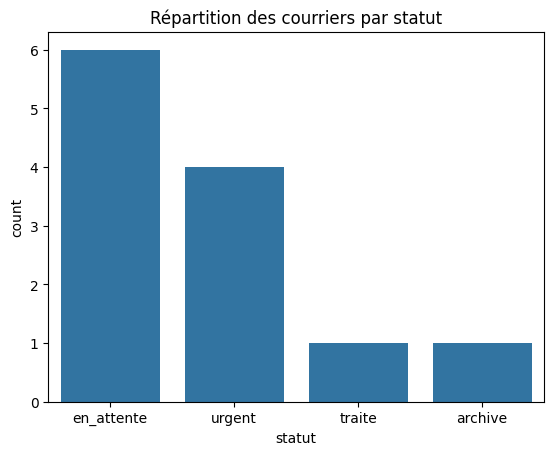

In [7]:
sns.countplot(
    x="statut",
    data=df
)

plt.title("Répartition des courriers par statut")
plt.show()

Analyse priorité

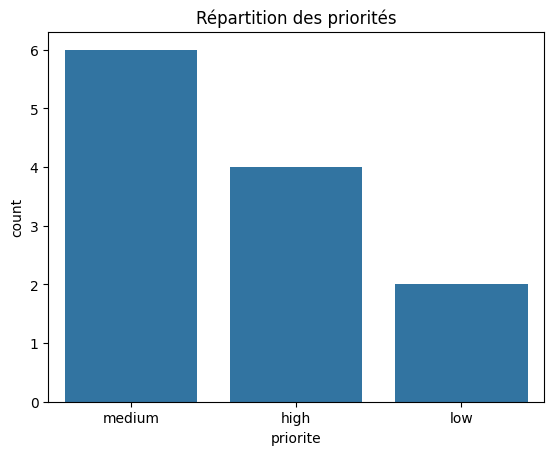

In [8]:
sns.countplot(
    x="priorite",
    data=df
)

plt.title("Répartition des priorités")
plt.show()

Feature Engineering

In [9]:
df['date_creation'] = pd.to_datetime(df['created_at'])

df['jour'] = df['date_creation'].dt.day
df['mois'] = df['date_creation'].dt.month

In [10]:
# priorite déjà encodée dans la base MySQL
df['priorite'].head()


0    medium
1      high
2       low
3      high
4    medium
Name: priorite, dtype: object

Exemple Machine Learning

In [11]:
df['statut'].unique()

array(['en_attente', 'urgent', 'traite', 'archive'], dtype=object)

In [ ]:
#df['Status_Code'] = df['statut'].map({
    #'en_attente':0,
    #'traite':1,
    #'urgent':2
#})


In [37]:
df['priorite'] = df['priorite'].map({
    'low':0,
    'medium':1,
    'high':2
})

In [38]:
df[['statut','Status_Code']].head(10)

,statut,Status_Code
0,en_attente,0.0
1,urgent,2.0
2,en_attente,0.0
3,traite,1.0
4,en_attente,0.0
5,urgent,2.0
6,urgent,2.0
7,en_attente,0.0
8,en_attente,0.0
9,en_attente,0.0


In [39]:
df['Status_Code'].value_counts()

Status_Code
0.0    6
2.0    4
1.0    1
Name: count, dtype: int64

In [40]:
df.dtypes

id                               int64
user_id                          int64
numero_reference                object
date_reception                  object
expediteur                      object
email                           object
objet                           object
contenu                         object
priorite                       float64
statut                          object
service_destinataire            object
scan_image_path                 object
scan_image_name                 object
scan_image_size                float64
scan_image_type                 object
original_filename               object
scan_score                       int64
scan_verdict                    object
created_at              datetime64[ns]
updated_at              datetime64[ns]
date_creation           datetime64[ns]
jour                             int32
mois                             int32
Status_Code                    float64
dtype: object

In [41]:
df['priorite'].unique()

array([nan])

Variables:

In [42]:
X = df[['priorite','jour','mois']]

y = df['Status_Code']

In [43]:
X.head()

,priorite,jour,mois
0,NaN,4,6
1,NaN,5,6
2,NaN,6,6
3,NaN,1,6
4,NaN,2,6


In [50]:
X.dtypes

priorite    float64
jour          int32
mois          int32
dtype: object

Train/Test:

In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

In [46]:
X_train.head()

,priorite,jour,mois
5,NaN,3,6
2,NaN,6,6
1,NaN,5,6
11,NaN,12,6
4,NaN,2,6


In [52]:
X_train.dtypes

priorite    float64
jour          int32
mois          int32
dtype: object

In [47]:
X_train.isna().sum()
y_train.isna().sum()

1

Model Utilise:

In [49]:
model = RandomForestClassifier()
model.fit(X_train,y_train)


ValueError: Input y contains NaN.

Evaluation du model:

In [20]:
prediction = model.predict(X_test)

accuracy_score(
    y_test,
    prediction
)

AttributeError: 'RandomForestClassifier' object has no attribute 'estimators_'